---
title: "Counting, Probability and Stirling's Approximation"
short_title: "T-M1 Counting & Stirling"
numbering:
  heading_2: true
  equation: true
---

# Counting, Probability and Stirling's Approximation

:::{tip} Where this sits in the plan
Math for **entropy and the second law**, **Boltzmann statistics** and the kinetic-theory parts of the thermo book (topics 1, 3 and 6). Statistical mechanics is counting: how many microscopic arrangements produce what you see.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Combinatorics | – | 15 | – | 23 |
| Probability and distributions | – | 15 | – | 23 |
| Stirling's approximation | 11 (series) | 11 | – | 12, 13 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Temperature, Ideal Gas, Kinetic Theory](../thermo/01-ideal-gas-kinetic-theory.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Counting Arrangements**

   (a) How many distinct arrangements are there of the letters in PHYSICS?

   (b) How many ways can you choose 3 particles out of 10?

   (c) An Einstein solid has 4 oscillators sharing 3 identical energy units. Find its multiplicity.

2. **Probability Distributions**

   (a) In 10 fair coin flips, find the mean and standard deviation of the number of heads.

   (b) Find the probability of exactly two sixes in five rolls of a die.

   (c) A random walker takes $10^4$ steps of 1 m. Roughly how far from the start does it end up?

3. **Stirling's Approximation**

   (a) Estimate $\ln(100!)$ with $N\ln N - N$, then add the $\tfrac12\ln(2\pi N)$ correction. The exact value is 363.74.

   (b) Use Stirling to find $\ln\binom{N}{N/2}$ to leading order for large $N$.

   (c) How does the relative width of a multiplicity peak scale with $N$?

4. **Very Large Numbers**

   Take $\Omega = 10^{10^{23}}$. What happens to $\Omega$, and to $\ln\Omega$, if you multiply it by $10^{23}$?

:::{dropdown} Answers
1. (a) $7!/2! = 2520$ (the S appears twice).

   (b) $\binom{10}{3} = 120$.

   (c) $\binom{3 + 4 - 1}{3} = 20$.

2. (a) Mean $5$, and $\sigma = \sqrt{10/4} \approx 1.58$.

   (b) $\binom52\left(\tfrac16\right)^2\left(\tfrac56\right)^3 \approx 0.16$.

   (c) About $\sqrt{10^4} = 100$ m.

3. (a) $100\ln100 - 100 \approx 360.5$, and adding $\tfrac12\ln(200\pi) \approx 3.2$ gives $363.7$.

   (b) $N\ln2$.

   (c) It goes as $1/\sqrt N$.

4. $\Omega$ is still essentially $10^{10^{23}}$, since the exponent becomes $10^{23} + 23$. Likewise $\ln\Omega$ changes by $23\ln10$, a negligible fraction of $10^{23}\ln10$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Counting Arrangements

Three rules cover almost everything in the thermo book.

- **Ordered arrangements (permutations).** $N$ distinct objects can be lined up in $N! = N(N-1)\cdots1$ ways: $N$ choices for the first slot, $N-1$ for the second, and so on.
- **Choosing a subset (combinations).** The number of ways to choose $n$ objects out of $N$, ignoring order, is

$$
\binom{N}{n} = \frac{N!}{n!\,(N-n)!} .
$$ (eq-binomial-coeff)

  Divide the $N!$ orderings by the $n!$ reorderings inside the chosen group and the $(N-n)!$ inside the rest.
- **Splitting into several groups (multinomial).** Splitting $N$ objects into groups of sizes $n_1, n_2, \ldots, n_k$ (with $\sum n_i = N$) can be done in $N!/(n_1!\,n_2!\cdots n_k!)$ ways.

:::{prf:definition} Multiplicity
:label: def-multiplicity-tm1

A **microstate** is a complete specification of every particle; a **macrostate** is what you measure (total energy, number of heads, ...). The **multiplicity** $\Omega$ of a macrostate is the number of microstates that produce it.
:::

For $N$ coins, the macrostate "$n$ heads" has $\Omega(n) = \binom{N}{n}$. Summing over all $n$ gives $2^N$, the total number of microstates, which is the binomial theorem $(1 + 1)^N = \sum_n\binom{N}{n}$.

::::{prf:example} Balls into boxes (stars and bars)
:label: ex-stars-bars

In how many ways can $q$ identical units of energy be shared among $N$ distinguishable oscillators? (This is the count behind the Einstein solid in thermo topic 3.)

:::{dropdown} Solution
Write the units as dots and separate the $N$ oscillators with $N - 1$ bars, for example $\bullet\bullet|\,|\bullet|\bullet\bullet\bullet$ for $q = 6$, $N = 4$. Every arrangement of $q$ dots and $N - 1$ bars is one way to share the energy, and vice versa. There are $q + N - 1$ symbols, and choosing which $q$ are dots fixes the arrangement:

$$
\Omega(N, q) = \binom{q + N - 1}{q} .
$$ (eq-stars-bars)

For $N = 4$ and $q = 6$: $\binom{9}{6} = 84$.
:::
::::

In [2]:
from math import comb
from itertools import product

# Brute-force check of stars and bars: count every (n1, ..., nN) with sum q
N, q = 4, 6
brute = sum(1 for ns in product(range(q + 1), repeat=N) if sum(ns) == q)
display(Math(rf"\text{{brute force}} = {brute},\qquad \binom{{q+N-1}}{{q}} = {comb(q + N - 1, q)}"))

<IPython.core.display.Math object>

## Probability Distributions

A **discrete distribution** assigns probabilities $P(x_i)$ with $\sum_iP(x_i) = 1$. A **continuous distribution** has a density $p(x)$: the probability of landing in $[x, x + dx]$ is $p(x)\,dx$, and $\int p\,dx = 1$. In both cases:

$$
\langle f\rangle = \sum_i f(x_i)P(x_i)\quad\text{or}\quad\int f(x)\,p(x)\,dx ,
\qquad
\sigma^2 = \langle x^2\rangle - \langle x\rangle^2 .
$$ (eq-mean-variance)

The standard deviation $\sigma$ measures the width of the distribution.

**The binomial distribution.** Flip $N$ independent coins, each landing heads with probability $p$. The probability of $n$ heads is

$$
P(n) = \binom{N}{n}p^n(1-p)^{N-n},\qquad \langle n\rangle = Np,\qquad \sigma^2 = Np(1-p) .
$$ (eq-binomial-dist)

The mean grows like $N$ but the width only like $\sqrt N$, so the **relative width** $\sigma/\langle n\rangle$ shrinks like $1/\sqrt N$. For $N\sim10^{23}$ the relative width is about $10^{-12}$: a macroscopic system sits essentially at its most probable macrostate. This is the whole reason thermodynamics works.

**The Gaussian limit.** For large $N$ the binomial distribution approaches a Gaussian with the same mean and variance:

$$
P(n) \approx \frac{1}{\sqrt{2\pi\sigma^2}}\,e^{-(n - \langle n\rangle)^2/2\sigma^2} .
$$ (eq-gaussian-limit)

This is a special case of the central limit theorem: a sum of many independent random pieces is Gaussian, whatever each piece's distribution.

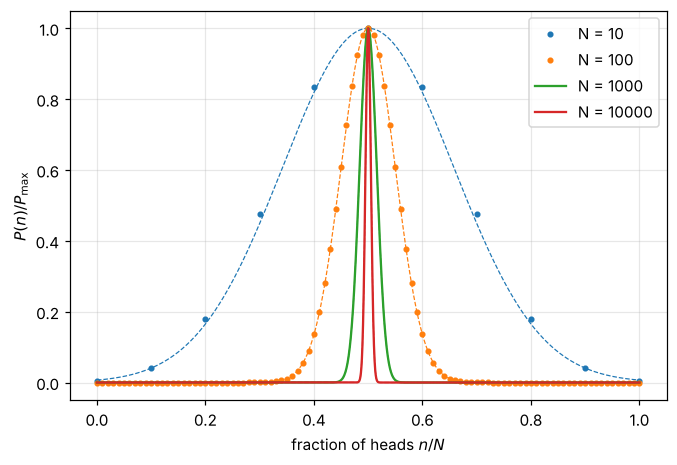

In [3]:
#| label: fig-binomial-sharpening
#| caption: "Binomial distributions for N fair coins, plotted against the fraction of heads n/N, each scaled to a peak height of 1. The peak narrows like 1/√N; dashed curves are the Gaussian approximation."
from scipy.stats import binom
fig, ax = plt.subplots()
for N, col in [(10, "tab:blue"), (100, "tab:orange"), (1000, "tab:green"), (10000, "tab:red")]:
    n = np.arange(N + 1)
    P = binom.pmf(n, N, 0.5)
    ax.plot(n / N, P / P.max(), "o" if N <= 100 else "-", ms=3, color=col, label=f"N = {N}")
    s = np.sqrt(N) / 2
    x = np.linspace(0, 1, 800)
    ax.plot(x, np.exp(-(x * N - N / 2)**2 / (2 * s**2)), "--", color=col, lw=0.8)
ax.set_xlabel("fraction of heads $n/N$"); ax.set_ylabel("$P(n)/P_{\\max}$"); ax.legend(); plt.show()

::::{prf:example} The random walk
:label: ex-random-walk-tm1

A molecule in a gas takes $N$ steps of length $\ell$, each equally likely to go left or right. How far from the start is it, typically?

:::{dropdown} Solution
The displacement is $x = \ell(n_R - n_L) = \ell(2n_R - N)$, with $n_R$ binomial ($p = 1/2$). So $\langle x\rangle = 0$ and

$$
\sigma_x = 2\ell\,\sigma_{n_R} = 2\ell\sqrt{N/4} = \ell\sqrt N .
$$

The walker gets about $\sqrt N$ steps from home, not $N$. If steps take time $\tau$, then $N = t/\tau$ and $\sigma_x = \ell\sqrt{t/\tau}$: distance grows like $\sqrt t$, the signature of diffusion.
:::
::::

## Stirling's Approximation

Multiplicities involve factorials of enormous numbers, and we need their logarithms. Stirling's approximation is

$$
\ln N! \approx N\ln N - N + \tfrac12\ln(2\pi N) ,
\qquad\text{or}\qquad
N! \approx \sqrt{2\pi N}\,N^Ne^{-N} .
$$ (eq-stirling)

For $N\sim10^{23}$, the term $\tfrac12\ln(2\pi N)\approx 27$ is negligible next to $N\ln N\sim 5\times10^{24}$, and the thermo book usually keeps only $N\ln N - N$.

:::{prf:proof} Two derivations
:class: dropdown

*Crude version.* $\ln N! = \sum_{k=1}^N\ln k$. The sum is close to the area under $\ln x$:

$$
\ln N! \approx \int_1^N\ln x\,dx = \big[x\ln x - x\big]_1^N = N\ln N - N + 1 .
$$

*Better version (Laplace's method).* Start from the Gamma-function integral (T-M2), $N! = \int_0^\infty x^Ne^{-x}\,dx$. The integrand $e^{f(x)}$ with $f = N\ln x - x$ has a sharp peak at $x = N$, where $f = N\ln N - N$ and $f'' = -1/N$. Expanding to second order around the peak, $f\approx N\ln N - N - (x - N)^2/2N$, and the Gaussian integral gives

$$
N! \approx e^{N\ln N - N}\int_{-\infty}^\infty e^{-u^2/2N}\,du = N^Ne^{-N}\sqrt{2\pi N} .
$$
:::

The second derivation is worth remembering as a method: **an integral of $e^{Nf(x)}$ with large $N$ is dominated by the maximum of $f$**, and the Gaussian width around the maximum supplies the prefactor. The same idea makes the most probable macrostate dominate a sum over macrostates.

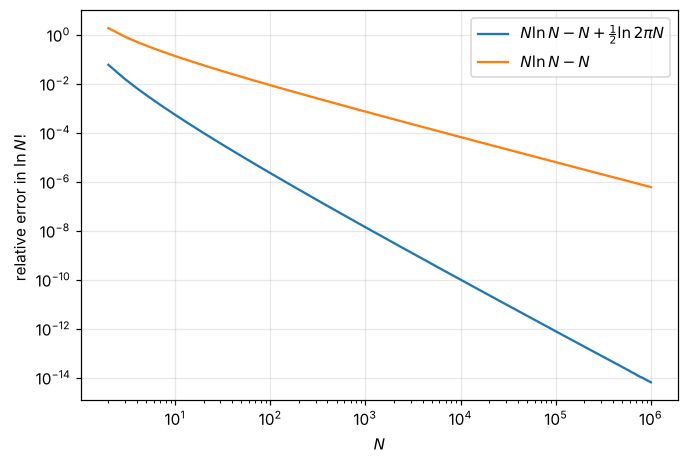

In [4]:
#| label: fig-stirling-error
#| caption: "Relative error of Stirling's approximation for ln N!. With the ½ ln(2πN) term (blue) the error falls roughly like 1/N² and is below 0.1% by N = 10; without it (orange) the error falls only like ln N / N."
from scipy.special import gammaln
N = np.unique(np.logspace(0.31, 6, 200).astype(int)); N = N[N >= 2]
exact = gammaln(N + 1)
full = N * np.log(N) - N + 0.5 * np.log(2 * np.pi * N)
crude = N * np.log(N) - N
fig, ax = plt.subplots()
ax.loglog(N, np.abs(full - exact) / exact, label=r"$N\ln N - N + \frac{1}{2}\ln 2\pi N$")
ax.loglog(N, np.abs(crude - exact) / exact, label=r"$N\ln N - N$")
ax.set_xlabel("$N$"); ax.set_ylabel("relative error in $\\ln N!$"); ax.legend(); plt.show()

::::{prf:example} The width of a multiplicity peak, from Stirling
:label: ex-peak-width-stirling

Use Stirling's approximation to show that $\Omega(n) = \binom{N}{n}$ near its peak is a Gaussian of width $\sqrt N/2$.

:::{dropdown} Solution
With $x = n/N$ and the crude Stirling formula,

$$
\ln\Omega = \ln N! - \ln n! - \ln(N - n)! \approx -N\big[x\ln x + (1 - x)\ln(1 - x)\big] .
$$

The bracket is minimized at $x = \tfrac12$, where $\ln\Omega = N\ln2$. Taylor-expand around there: the second derivative of $-[x\ln x + (1-x)\ln(1-x)]$ is $-1/x - 1/(1-x) = -4$ at $x = \tfrac12$. So, with $n - N/2 = N(x - \tfrac12)$,

$$
\ln\Omega \approx N\ln2 - 2N\left(x - \tfrac12\right)^2 = N\ln 2 - \frac{2(n - N/2)^2}{N} ,
$$

a Gaussian $e^{-(n - N/2)^2/2\sigma^2}$ with $\sigma^2 = N/4$. This matches the binomial variance $Np(1-p)$ with $p = 1/2$.
:::
::::

In [5]:
# The same expansion done by SymPy: second derivative of ln(Omega)/N at x = 1/2
x, Nn = sp.symbols("x N", positive=True)
lnOmega_per_N = -(x * sp.log(x) + (1 - x) * sp.log(1 - x))
d2 = sp.simplify(sp.diff(lnOmega_per_N, x, 2).subs(x, sp.Rational(1, 2)))
display(Math(r"\frac{1}{N}\frac{d^2\ln\Omega}{dx^2}\Big|_{x=1/2} = " + sp.latex(d2)))

<IPython.core.display.Math object>

## Very Large Numbers

Statistical mechanics deals with three sizes of number, and it helps to keep them apart.

| Kind | Example | Rule of thumb |
|---|---|---|
| small | 2, 37, $\tfrac32$ | ordinary arithmetic |
| large | $N = 10^{23}$ | adding a small number changes nothing: $10^{23} + 37 \approx 10^{23}$ |
| very large | $\Omega = 10^{10^{23}}$ | multiplying by a large number changes nothing: $10^{23}\times10^{10^{23}} = 10^{10^{23} + 23}\approx 10^{10^{23}}$ |

That last row is why entropy is defined as a logarithm (thermo topic 3): $\ln\Omega$ turns very large numbers into large ones, and the factors we lose (like $\sqrt{2\pi N}$ in Stirling) become additive terms of size $\ln N$, utterly negligible next to $N$.

### Exercises

1. How many distinct ways can the letters of STATISTICS be arranged?
2. An Einstein solid has $N = 3$ oscillators and $q = 4$ energy units. List the possible occupation patterns up to order (e.g. $(4,0,0)$, $(3,1,0)$, ...), count the arrangements of each, and check that they add to $\binom{q+N-1}{q}$.
3. Use the full Stirling formula to estimate $\binom{100}{50}$, and compare with the exact value $1.0089\times10^{29}$.
4. A drunk takes 10 000 steps of 0.5 m. Roughly how far from the lamppost does he end up? How many steps would he need to get 1 km away?
5. Show that the probability of exactly $N/2$ heads in $N$ fair flips is about $\sqrt{2/(\pi N)}$. What is it for $N = 10^{20}$?

:::{dropdown} Hints
1. Count repeated letters: S ×3, T ×3, I ×2, A, C.
2. Patterns: $(4,0,0)$, $(3,1,0)$, $(2,2,0)$, $(2,1,1)$. The number of arrangements of each is $3!$ divided by the factorial of each repeated count.
3. Write $\binom{100}{50} = 100!/(50!)^2$ and apply $N!\approx\sqrt{2\pi N}N^Ne^{-N}$ to each factorial.
4. $\sigma = \ell\sqrt N$.
5. Use the result for $\binom{N}{N/2}$ from Stirling, then divide by $2^N$.
:::

:::{dropdown} Answers
1. $10!/(3!\,3!\,2!) = 50\,400$.
2. $(4,0,0)$: 3; $(3,1,0)$: 6; $(2,2,0)$: 3; $(2,1,1)$: 3. Total $15 = \binom{6}{4}$.
3. $\binom{100}{50}\approx 2^{100}/\sqrt{50\pi} = 1.0114\times10^{29}$, about 0.25% high (the next term of Stirling's series fixes most of this).
4. $0.5\sqrt{10^4} = 50$ m. For 1 km he needs $(1000/0.5)^2 = 4\times10^6$ steps.
5. $\binom{N}{N/2}\approx 2^N\sqrt{2/(\pi N)}$, so $P\approx\sqrt{2/\pi N}$; for $N = 10^{20}$, $P\approx 8\times10^{-11}$. Even the most probable outcome is improbable; what is overwhelmingly probable is landing within a few $\sqrt N$ of it.
:::

## Summary

- $N!$ orderings, $\binom Nn$ subsets, $\binom{q+N-1}{q}$ ways to share $q$ identical units among $N$ boxes.
- A distribution is summarized by its mean and variance; for $N$ independent pieces, the mean grows like $N$ and the width like $\sqrt N$.
- Large-$N$ multiplicities are Gaussians, sharply peaked: relative width $\sim1/\sqrt N$.
- Stirling: $\ln N!\approx N\ln N - N$ (plus $\tfrac12\ln2\pi N$ when you need it). Laplace's method, expanding an exponent around its maximum, is the general tool behind it.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.